<a href="https://colab.research.google.com/github/venkatasai-eng/Computer-Vision/blob/main/Exp_28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving car-video.mp4 to car-video.mp4


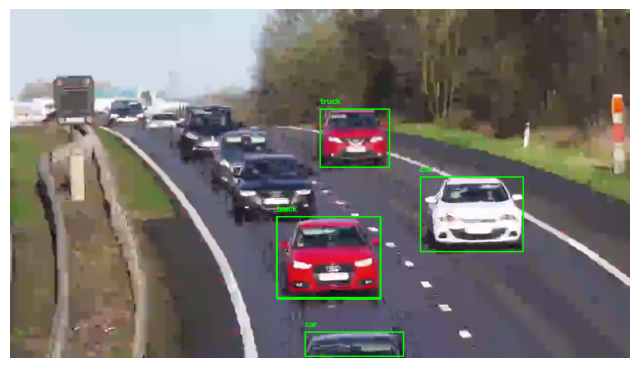

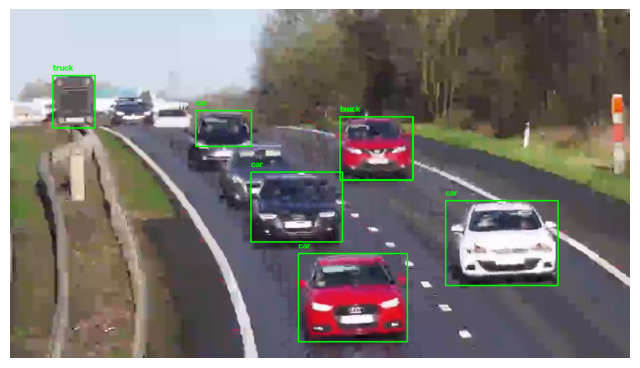

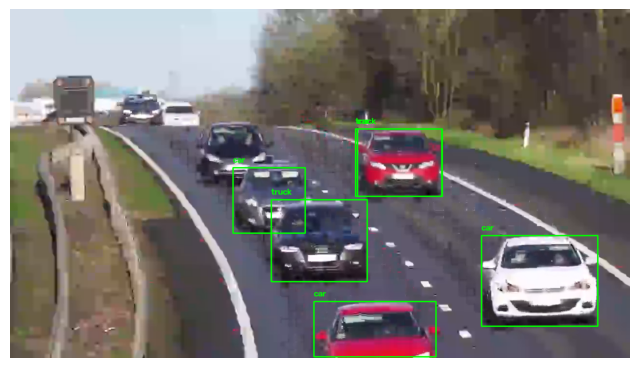

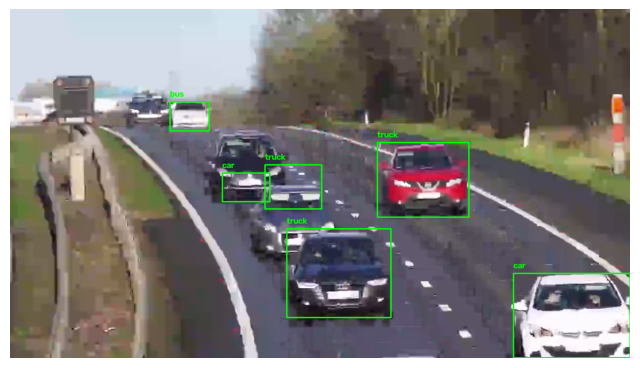

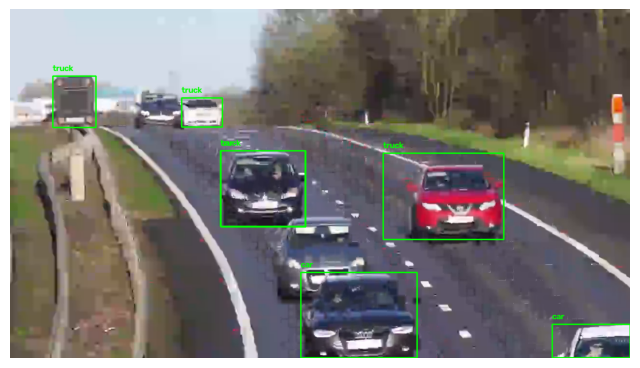

In [ ]:
!pip install -q ultralytics

import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files

uploaded = files.upload()
cap = cv2.VideoCapture(next(iter(uploaded)))
model = YOLO("yolov8n.pt")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    results = model(frame, verbose=False)

    for box in results[0].boxes:
        cls = int(box.cls[0])
        if cls in [2, 3, 5, 7]:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(frame, model.names[cls], (x1, y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    if int(cap.get(cv2.CAP_PROP_POS_FRAMES)) % 30 == 0:
        plt.figure(figsize=(8, 5))
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()

cap.release()